In [1]:
import json
import sys
from pathlib import Path

project_root = Path("../../..").resolve()
sys.path.append(str(project_root))


import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, train_test_split

from utils import DataManager, exclude_column
from utils.plotter import actual_vs_prediction, feature_importance, y_fdistro


In [2]:
COLUMNS = project_root / 'models' / 'random_forest' / 'admet' / 'admet_columns.json'

In [3]:
df = DataManager(path="admet/solubility").dataset

with open(str(COLUMNS), 'r') as f:
    data = json.load(f)

df = df[data['columns']]

In [4]:
fp_cols = [col for col in df.columns if col.startswith("fp_")]
unique_cols = df[fp_cols].nunique()
constant_cols = unique_cols[unique_cols == 1]

# exclude_column(path=COLUMNS, col_name="cyp3a4", col=list(constant_cols.index))
# df = df.drop(columns=constant_cols.index)
# constant_cols

In [5]:
null = (df.isnull()).sum().sum()
null

np.int64(0)

In [6]:
X = df.drop(columns='label')
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=25)

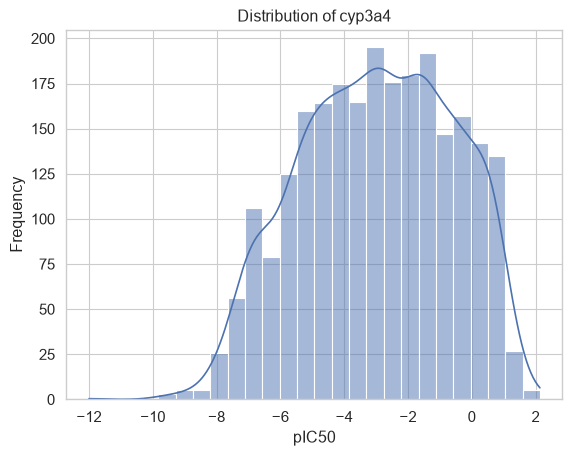

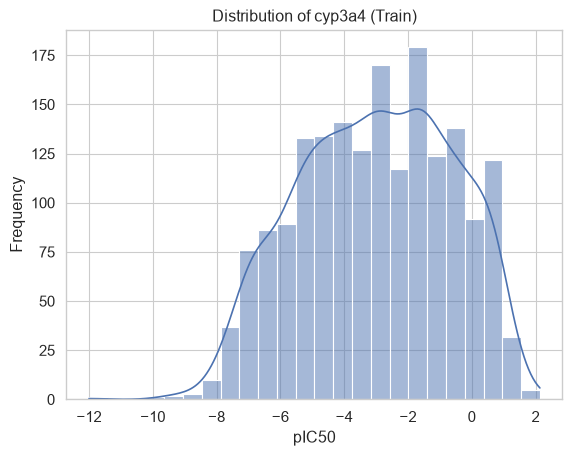

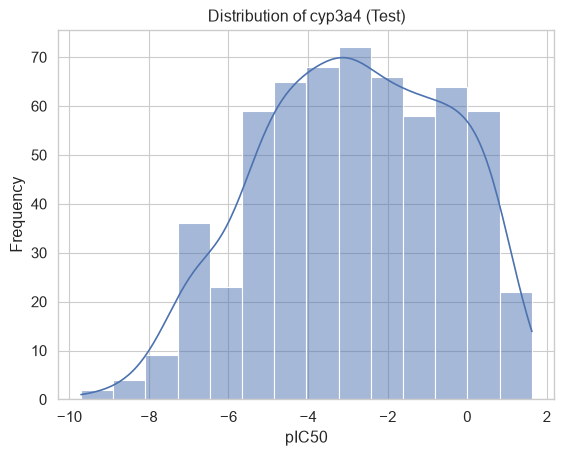

In [7]:
y_fdistro(y, "cyp3a4")
y_fdistro(y_train, "cyp3a4 (Train)")
y_fdistro(y_test, "cyp3a4 (Test)")

In [8]:
# model = RandomForestRegressor(
#     random_state=42,
#     n_jobs=-1
# )

# param_grid = {
#     "n_estimators": [1500, 2000, 2500],
#     "max_depth": [None, 5, 10, 20, 30, 50],
#     "min_samples_split": [2, 5, 10, 15],
#     "min_samples_leaf": [1, 2, 4, 8],
#     "max_features": ["sqrt", "log2", 0.2, 0.5, 0.8, 1.0],
#     "max_samples": [None, 0.6, 0.8, 1.0]
# }

# search = RandomizedSearchCV(
#     model,
#     param_distributions=param_grid,
#     n_iter=50,
#     scoring="neg_root_mean_squared_error",
#     cv=5,
#     random_state=42,
#     n_jobs=-1
# )

# search.fit(X_train, y_train)
# print(search.best_params_)
# print(search.best_score_)



In [9]:
best_model = RandomForestRegressor(
    n_estimators=100,
    min_samples_split=2,
    min_samples_leaf=1, 
    max_samples=0.6,
    max_features=0.2,
    max_depth=20 
)

best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

In [10]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'RMSE: {rmse}')
print(f'MSE: {mse}')
print(f'MAE: {mae}')
print(f'R2: {r2}')


RMSE: 1.1465941752089743
MSE: 1.3146782026231483
MAE: 0.8368734270592127
R2: 0.761139392614275


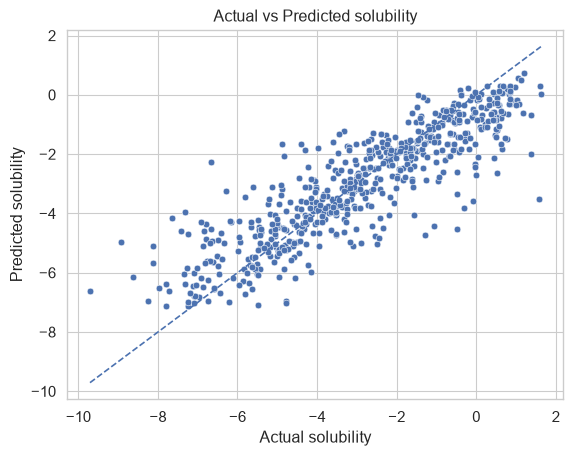

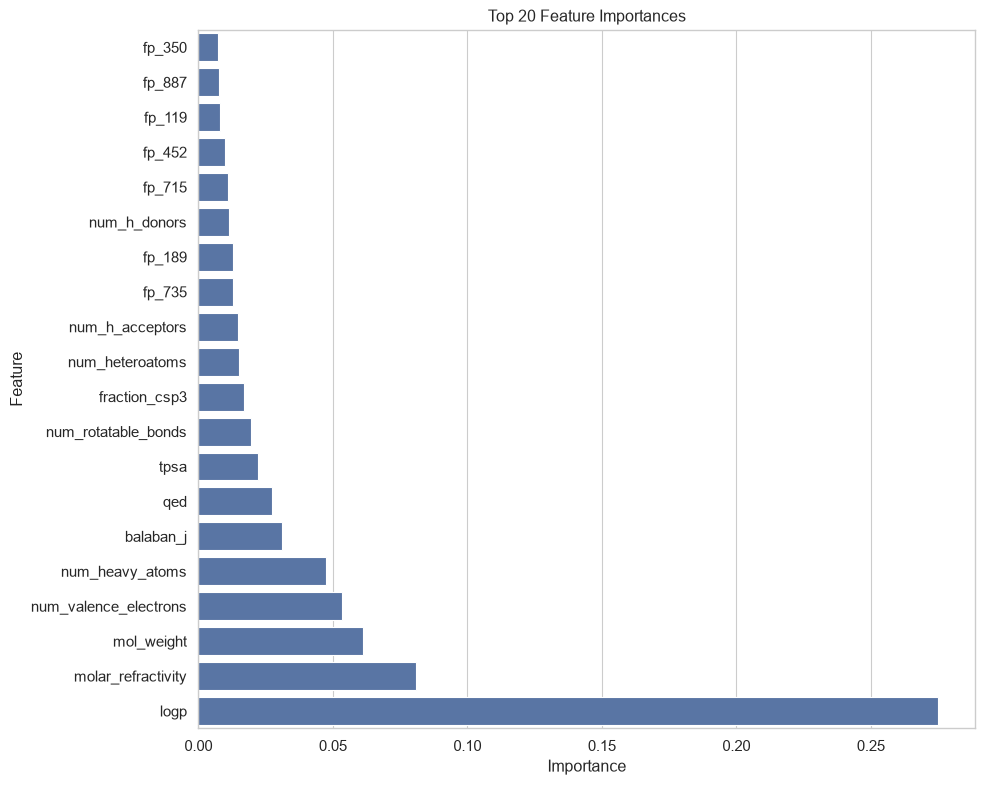

,Feature,Importance
366,fp_350,0.007252
903,fp_887,0.007709
135,fp_119,0.007971
468,fp_452,0.010050
731,fp_715,0.011015
3,num_h_donors,0.011450
205,fp_189,0.012758
751,fp_735,0.012815
4,num_h_acceptors,0.014824
12,num_heteroatoms,0.015206


In [11]:
actual_vs_prediction(y_test, y_pred, name='solubility')
feature_importance(best_model, X_train.columns)

In [12]:
import pandas as pd
inf_df = DataManager('roselle_dataset').dataset

with open('admet_columns_inference.json', 'r') as f:
    data = json.load(f)

inf_df = inf_df[data['columns']]

preds = best_model.predict(inf_df)
preds = pd.DataFrame(preds, columns=['solubility'])
preds

,solubility
0,-0.671951
1,-0.402416
2,-0.998958
3,-0.785239
4,-0.641728
...,...
1279,-4.422295
1280,-3.435670
1281,-3.188081
1282,-3.606325


In [13]:
final_dataset = pd.read_csv(project_root / 'data' / 'final_dataset' / 'final_roselle_dataset.csv')
final_dataset = pd.concat(objs=[final_dataset, preds], axis=1)

output = project_root / 'data' / 'final_dataset'
# output.mkdir(parents=True, exist_ok=True)

output_file = output / 'final_roselle_dataset.csv'
final_dataset.to_csv(output_file, index=False)
# final_dataset
